In [1]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.utils import to_categorical
from matplotlib import pyplot as plt
import numpy as np


I0000 00:00:1785828496.213021    1164 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785828496.213825    1164 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1785828496.291847    1164 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1785828498.208363    1164 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785828498.208809    1164 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Load the MNIST dataset

In [3]:
(train_data,train_target),(test_data,test_target) = mnist.load_data()

Visualize the dataset

Target labels:  [8 3 3 0 2 9 9 0 9 0]


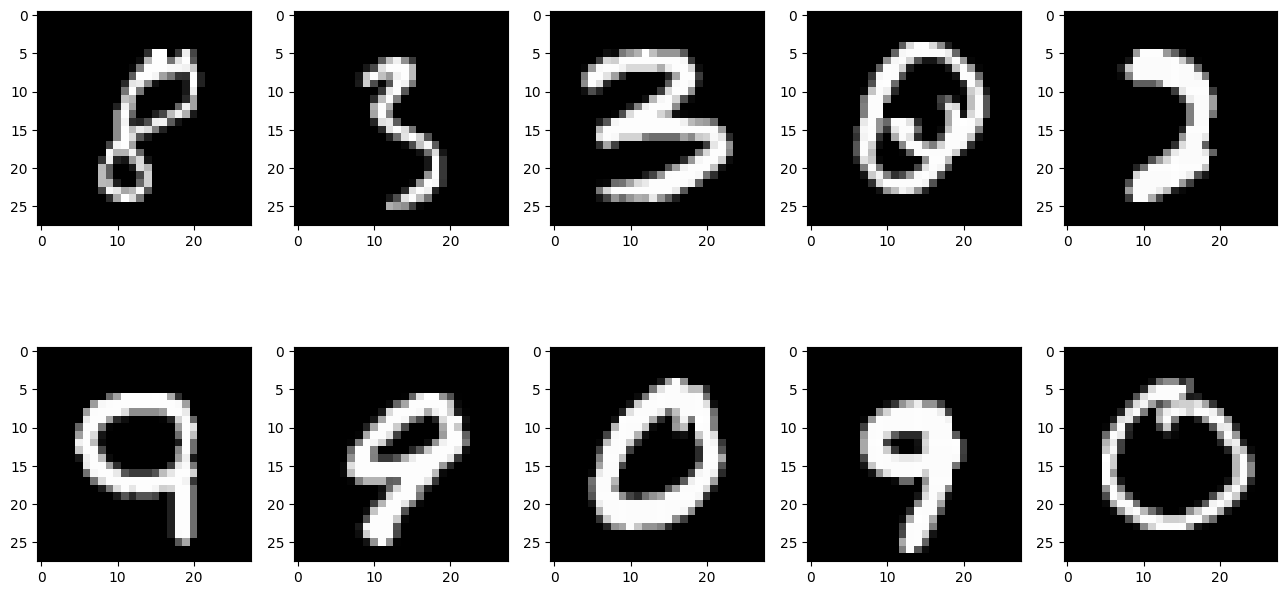

In [4]:
fig, axs = plt.subplots(2, 5, figsize=(16,8))
random_numbers = np.random.randint(0, 60000, 10)
print('Target labels: ',train_target[random_numbers])
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(train_data[random_numbers[idx]],cmap='gray')
plt.show()

Pre-processing stage

In [5]:
new_train_data = train_data/255.0
new_test_data=test_data/255.0

new_train_target = to_categorical(train_target)
new_test_target = to_categorical(test_target)

Create the Model architecture

In [6]:
model=Sequential()

model.add(Flatten(input_shape=(28,28)))

model.add(Dense(64,activation='relu'))
model.add(Dense(64,input_dim=64,activation='relu'))
model.add(Dense(32,input_dim=64,activation='relu'))
model.add(Dense(10,input_dim=32,activation='softmax'))
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1785828503.856047    1164 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,810 (221.91 KB)

 Trainable params: 56,810 (221.91 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [8]:
train_info = model.fit(new_train_data , new_train_target , epochs = 10)

Epoch 1/10


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 48:05 2s/step - accuracy: 0.0938 - loss: 2.2890

  26/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3065 - loss: 1.9758  

  52/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4892 - loss: 1.5825

  77/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5771 - loss: 1.3412

 103/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6459 - loss: 1.1383

... (742 outputs left out)

1809/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9889 - loss: 0.0327

1834/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9888 - loss: 0.0330

1859/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9888 - loss: 0.0331

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9888 - loss: 0.0330


Plot the loss and accuracy graphs

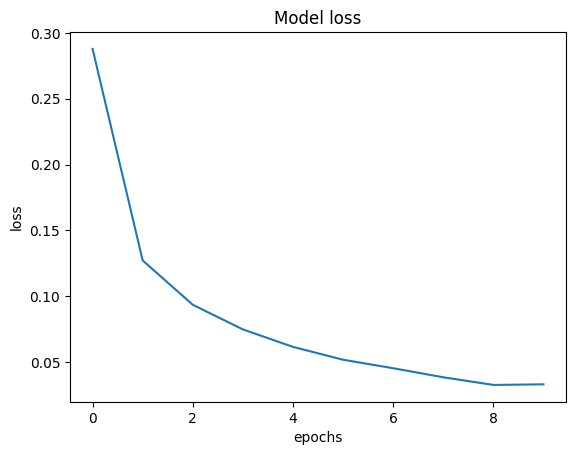

In [9]:
plt.plot(train_info.history['loss'])
plt.xlabel('epochs')
plt.ylabel('loss')
plt.title('Model loss')
plt.show()

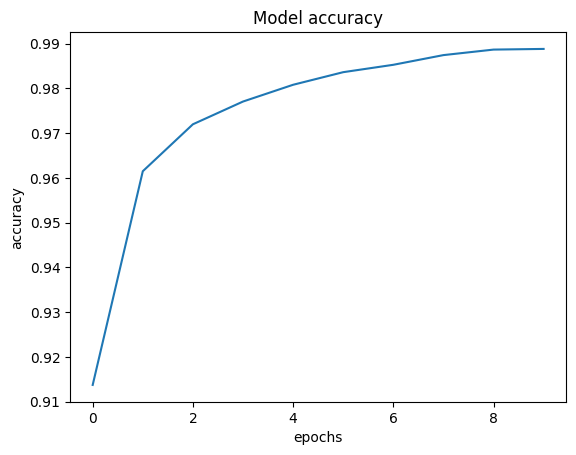

In [10]:
plt.plot(train_info.history['accuracy'])
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('Model accuracy')
plt.show()

Test the performance of Model

In [11]:
loss, acc = model.evaluate(new_test_data , new_test_target)
print(f'Loss of the Test dataset is: {loss}\nAccuracy of the test dataset is: {acc}')

  1/313 ━━━━━━━━━━━━━━━━━━━━ 1:00 195ms/step - accuracy: 1.0000 - loss: 0.0018

 33/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9697 - loss: 0.1279    

 66/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9640 - loss: 0.1486

 98/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9643 - loss: 0.1475

132/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9645 - loss: 0.1377

165/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9655 - loss: 0.1320

... (2 outputs left out)

265/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9712 - loss: 0.1112

299/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9739 - loss: 0.1046

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9731 - loss: 0.1096


Loss of the Test dataset is: 0.10956386476755142
Accuracy of the test dataset is: 0.9731000065803528


## Improving Test Accuracy (Hyperparameter Tuning)

The baseline model above uses 3 hidden layers (64, 64, 32 units), Adam optimizer, and only 10 epochs with no validation split. To improve test accuracy we:
- widen the hidden layers (128, 64, 32)
- train for more epochs (20 instead of 10)
- add a `validation_split` so we can monitor generalization while training
- use a slightly smaller `batch_size` (128) for more gradient updates per epoch


In [12]:
model_tuned = Sequential()
model_tuned.add(Flatten(input_shape=(28,28)))
model_tuned.add(Dense(128, activation='relu'))
model_tuned.add(Dense(64, activation='relu'))
model_tuned.add(Dense(32, activation='relu'))
model_tuned.add(Dense(10, activation='softmax'))
model_tuned.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_tuned.summary()

tuned_info = model_tuned.fit(
    new_train_data, new_train_target,
    epochs=20,
    batch_size=128,
    validation_split=0.1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (526 outputs left out)

377/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9961 - loss: 0.0117

394/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9961 - loss: 0.0117

412/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9960 - loss: 0.0118

422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9960 - loss: 0.0121 - val_accuracy: 0.9755 - val_loss: 0.1212


In [13]:
tuned_loss, tuned_acc = model_tuned.evaluate(new_test_data, new_test_target)
print(f'[Tuned model] Test loss: {tuned_loss:.4f}, Test accuracy: {tuned_acc:.4f}')
print(f'[Baseline model] Test loss: {loss:.4f}, Test accuracy: {acc:.4f}')

  1/313 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9688 - loss: 0.0352

 33/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9763 - loss: 0.1155 

 66/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9659 - loss: 0.1628

 97/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9646 - loss: 0.1709

129/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9673 - loss: 0.1649

161/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9656 - loss: 0.1634

... (2 outputs left out)

259/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9721 - loss: 0.1344

291/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9744 - loss: 0.1259

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9737 - loss: 0.1281


[Tuned model] Test loss: 0.1281, Test accuracy: 0.9737
[Baseline model] Test loss: 0.1096, Test accuracy: 0.9731


## Adding L1 and L2 Regularization

We take the same tuned architecture and add `kernel_regularizer=l1_l2(...)` to each hidden Dense layer. This penalizes large weights during training (L1 encourages sparsity, L2 shrinks weights smoothly), which should reduce overfitting and the gap between training and validation accuracy.

In [14]:
from tensorflow.keras.regularizers import l1_l2

model_reg = Sequential()
model_reg.add(Flatten(input_shape=(28,28)))
model_reg.add(Dense(128, activation='relu', kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)))
model_reg.add(Dense(64, activation='relu', kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)))
model_reg.add(Dense(32, activation='relu', kernel_regularizer=l1_l2(l1=1e-5, l2=1e-4)))
model_reg.add(Dense(10, activation='softmax'))
model_reg.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_reg.summary()

reg_info = model_reg.fit(
    new_train_data, new_train_target,
    epochs=20,
    batch_size=128,
    validation_split=0.1
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (575 outputs left out)

376/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9949 - loss: 0.0750

391/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9947 - loss: 0.0755

407/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9945 - loss: 0.0758

422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9944 - loss: 0.0763 - val_accuracy: 0.9767 - val_loss: 0.1450


In [15]:
reg_loss, reg_acc = model_reg.evaluate(new_test_data, new_test_target)
print(f'[L1/L2 regularized model] Test loss: {reg_loss:.4f}, Test accuracy: {reg_acc:.4f}')
print(f'[Tuned model, no regularization] Test loss: {tuned_loss:.4f}, Test accuracy: {tuned_acc:.4f}')
print(f'[Baseline model] Test loss: {loss:.4f}, Test accuracy: {acc:.4f}')

  1/313 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9688 - loss: 0.1434

 27/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9722 - loss: 0.1655 

 55/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9631 - loss: 0.1841

 85/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9640 - loss: 0.1841

116/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9674 - loss: 0.1774

145/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9666 - loss: 0.1760

... (3 outputs left out)

261/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9747 - loss: 0.1473

291/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9767 - loss: 0.1403

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9761 - loss: 0.1445


[L1/L2 regularized model] Test loss: 0.1445, Test accuracy: 0.9761
[Tuned model, no regularization] Test loss: 0.1281, Test accuracy: 0.9737
[Baseline model] Test loss: 0.1096, Test accuracy: 0.9731


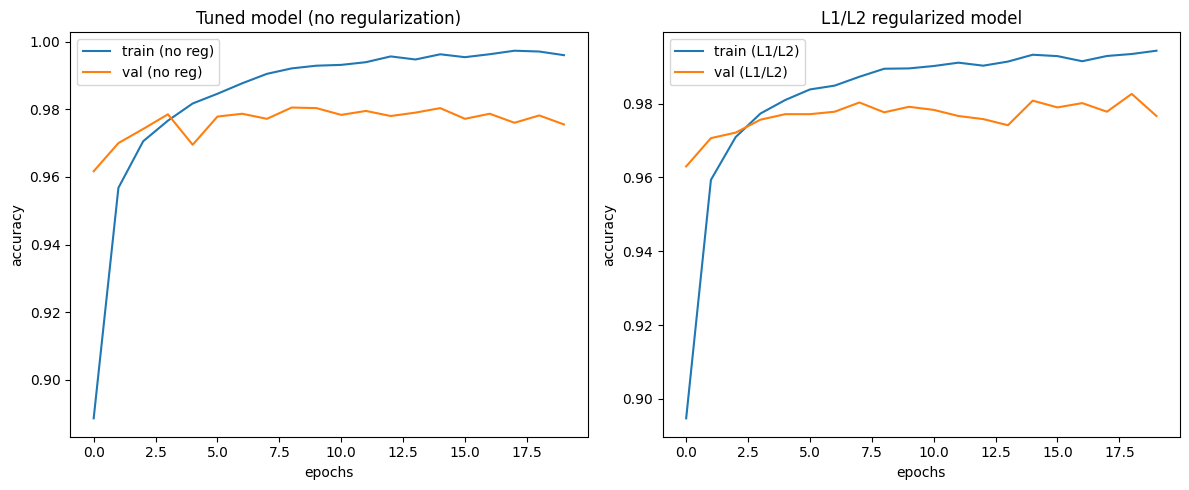

In [16]:
# Compare training vs validation accuracy to see the effect of regularization on overfitting
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(tuned_info.history['accuracy'], label='train (no reg)')
plt.plot(tuned_info.history['val_accuracy'], label='val (no reg)')
plt.xlabel('epochs'); plt.ylabel('accuracy'); plt.title('Tuned model (no regularization)')
plt.legend()

plt.subplot(1,2,2)
plt.plot(reg_info.history['accuracy'], label='train (L1/L2)')
plt.plot(reg_info.history['val_accuracy'], label='val (L1/L2)')
plt.xlabel('epochs'); plt.ylabel('accuracy'); plt.title('L1/L2 regularized model')
plt.legend()

plt.tight_layout()
plt.show()

## Class-wise Performance: Confusion Matrix

We use the final regularized model to predict on the test set, then build a confusion matrix to see which digits are most often confused with each other.

  1/313 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step

 41/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

 82/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

124/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

167/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

210/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

252/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

294/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


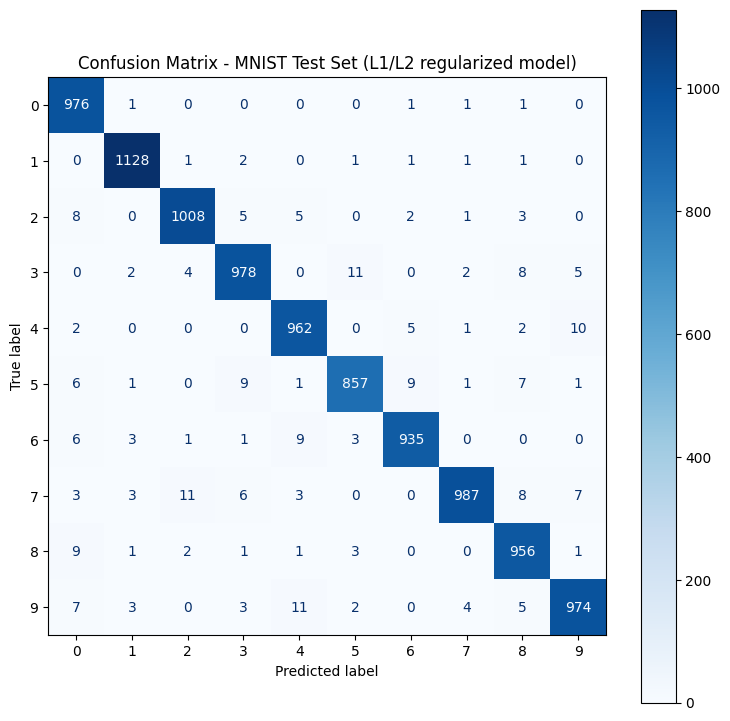

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_pred_probs = model_reg.predict(new_test_data)
test_pred_labels = np.argmax(test_pred_probs, axis=1)

cm = confusion_matrix(test_target, test_pred_labels)

fig, ax = plt.subplots(figsize=(9,9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(ax=ax, cmap='Blues', colorbar=True)
plt.title('Confusion Matrix - MNIST Test Set (L1/L2 regularized model)')
plt.show()

In [18]:
from sklearn.metrics import classification_report
print(classification_report(test_target, test_pred_labels, digits=4))

              precision    recall  f1-score   support

           0     0.9597    0.9959    0.9775       980
           1     0.9877    0.9938    0.9908      1135
           2     0.9815    0.9767    0.9791      1032
           3     0.9731    0.9683    0.9707      1010
           4     0.9698    0.9796    0.9747       982
           5     0.9772    0.9608    0.9689       892
           6     0.9811    0.9760    0.9785       958
           7     0.9890    0.9601    0.9743      1028
           8     0.9647    0.9815    0.9730       974
           9     0.9760    0.9653    0.9706      1009

    accuracy                         0.9761     10000
   macro avg     0.9760    0.9758    0.9758     10000
weighted avg     0.9762    0.9761    0.9761     10000



Save the model weights

In [19]:
model.save_weights('MNIST_WEIGHTS_V1.weights.h5')